<a href="https://colab.research.google.com/github/marcelosantosjunior2027/IFOOD_GENAI_PORTIF-LIO/blob/main/Roteiriza%C3%A7%C3%A3o_de_Frota_com_Restri%C3%A7%C3%A3o_de_Capacidade_(CVRP).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

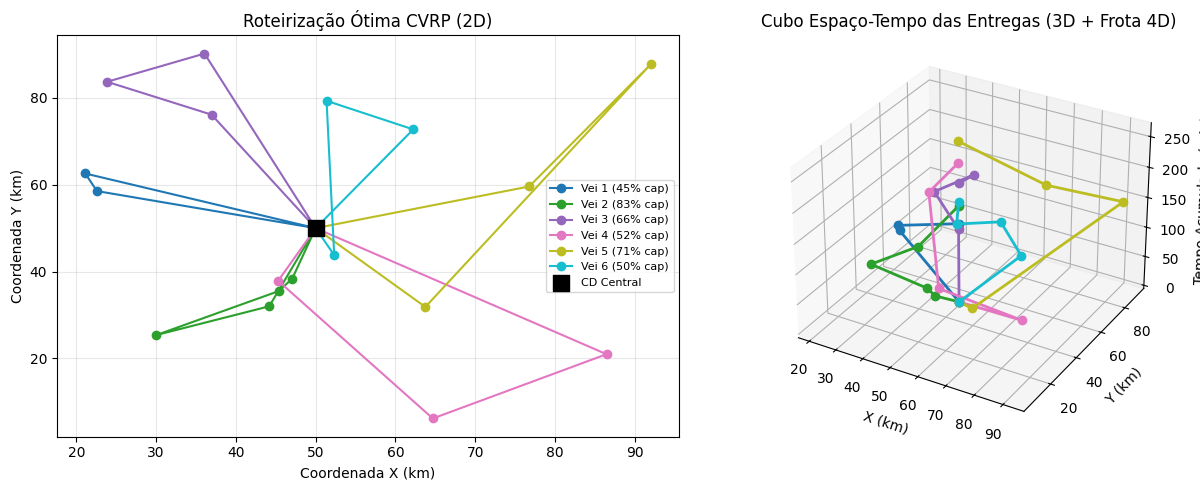

In [1]:
# AUTOR: MARCELO DE OLIVEIRA SANTOS JUNIOR
# DIMENSIONAMENTO DE ROTAS COM CAPACIDADE RESTRITA (CVRP)

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
n_clients = 18
depot = np.array([[50.0, 50.0]])
coords = np.vstack([depot, rng.uniform(5, 95, (n_clients, 2))])
demands = np.hstack([[0], rng.integers(120, 320, n_clients)])  # kg por cliente
truck_capacity = 1000

# Algoritmo de Clarke-Wright Savings
dist_matrix = np.linalg.norm(coords[:, None, :] - coords[None, :, :], axis=2)
routes = {i: [i] for i in range(1, n_clients + 1)}
route_loads = {i: demands[i] for i in range(1, n_clients + 1)}

savings = []
for i in range(1, n_clients + 1):
    for j in range(i + 1, n_clients + 1):
        s = dist_matrix[0, i] + dist_matrix[0, j] - dist_matrix[i, j]
        savings.append((s, i, j))
savings.sort(reverse=True)

for _, i, j in savings:
    ri = next((k for k, v in routes.items() if i in v), None)
    rj = next((k for k, v in routes.items() if j in v), None)
    if ri != rj and (route_loads[ri] + route_loads[rj] <= truck_capacity):
        if routes[ri][-1] == i and routes[rj][0] == j:
            routes[ri].extend(routes[rj])
            route_loads[ri] += route_loads[rj]
            del routes[rj], route_loads[rj]

fig = plt.figure(figsize=(13, 5))
ax1 = fig.add_subplot(1, 2, 1)
ax2 = fig.add_subplot(1, 2, 2, projection="3d")

colors = plt.cm.tab10(np.linspace(0, 1, len(routes)))
for idx, (r_id, seq) in enumerate(routes.items()):
    full_path = [0] + seq + [0]
    pts = coords[full_path]
    load_pct = (route_loads[r_id] / truck_capacity) * 100

    # 2D: Mapa de Rotas
    ax1.plot(pts[:, 0], pts[:, 1], marker="o", color=colors[idx], label=f"Vei {idx+1} ({load_pct:.0f}% cap)")

    # 3D/4D: Trajetória Espaço-Tempo (Z = Tempo acumulado em min)
    step_dists = np.linalg.norm(np.diff(pts, axis=0), axis=1)
    times_min = np.hstack([[0], np.cumsum(step_dists * 1.5 + 12)])  # 1.5 min/km + 12 min descarga
    ax2.plot(pts[:, 0], pts[:, 1], times_min, marker="o", color=colors[idx], lw=2)

ax1.scatter(50, 50, color="black", s=120, marker="s", zorder=5, label="CD Central")
ax1.set_title("Roteirização Ótima CVRP (2D)")
ax1.set_xlabel("Coordenada X (km)")
ax1.set_ylabel("Coordenada Y (km)")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

ax2.set_title("Cubo Espaço-Tempo das Entregas (3D + Frota 4D)")
ax2.set_xlabel("X (km)")
ax2.set_ylabel("Y (km)")
ax2.set_zlabel("Tempo Acumulado (min)")

plt.tight_layout()
plt.show()